In [ ]:
# Alzheimer's EEG Classification
#Classifying people as Alzheimer's or healthy from their resting EEG, using brain-wave power features.

In [10]:
# Gets all the tools we need
!pip install -q openneuro-py mne        # openneuro-py downloads the data, mne reads EEG files

import glob                              # finds files by name pattern
import numpy as np                       # arrays and maths
import pandas as pd                      # tables
import matplotlib.pyplot as plt          # plots
import mne                               # reads and filters EEG
import openneuro as on                   # downloads the dataset
from scipy.signal import welch           # measures how strong each wave speed is
from sklearn.pipeline import make_pipeline                  # chains steps together (scale -> model)
from sklearn.preprocessing import StandardScaler            # puts all numbers on the same scale
from sklearn.linear_model import LogisticRegression         # model 1
from sklearn.svm import SVC                                 # model 2 (SVM)
from sklearn.ensemble import RandomForestClassifier         # model 3
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_score, cross_val_predict   # testing tools
from sklearn.metrics import ConfusionMatrixDisplay          # draws the confusion matrix
mne.set_log_level("ERROR")               # hides MNE's long messages

In [11]:
# Downloads the small table that says who is Alzheimer's (A) and who is healthy (C)
on.download(dataset="ds004504", target_dir="ds004504", include=["participants.tsv"])
df = pd.read_csv("ds004504/participants.tsv", sep="\t")
df = df[df["Group"].isin(["A", "C"])].reset_index(drop=True)    # keep Alzheimer's and healthy, skip the third group (FTD)
print(df["Group"].value_counts())                                # should show A: 36 and C: 29

🌍 Preparing to download ds004504 …
📥 Checking 5 files, downloading as needed (5 concurrent downloads). 


Output()

✅ Finished downloading ds004504 (downloaded 0 files and 0 B).
Group
A    36
C    29
Name: count, dtype: int64


In [12]:
# Downloads the cleaned EEG files of those 65 people
on.download(dataset="ds004504", target_dir="ds004504",
            include=[f"derivatives/{s}" for s in df["participant_id"]])

🌍 Preparing to download ds004504 …
📥 Checking 70 files, downloading as needed (5 concurrent downloads). 


Output()

✅ Finished downloading ds004504 (downloaded 0 files and 0 B).


In [13]:
# Defines a function that reads one person's EEG and returns the numbers the model learns from.
# It does not run on anyone yet. Cell 5 uses it.

BANDS = {"delta": (0.5, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30)}   # wave types and their speeds in Hz
REGIONS = {                      # the 19 electrodes grouped into 5 brain areas
    "frontal":   ["Fp1", "Fp2", "F7", "F3", "Fz", "F4", "F8"],
    "central":   ["C3", "Cz", "C4"],
    "temporal":  ["T3", "T4", "T5", "T6"],
    "parietal":  ["P3", "Pz", "P4"],
    "occipital": ["O1", "O2"],
}

def get_features(path):
    # 1) read the recording, keep only 0.5-45 Hz (removes slow drift and fast noise), lower the sampling rate to 250 Hz
    raw = mne.io.read_raw_eeglab(path, preload=True)
    raw.filter(0.5, 45.0)
    raw.resample(250)
    names = [n.lower() for n in raw.ch_names]

    # 2) power at each frequency, for every electrode
    #    (Welch cuts the signal into 4 second pieces and averages them, which gives a steadier result)
    freqs, psd = welch(raw.get_data(), fs=250, nperseg=1000)
    total = (freqs >= 0.5) & (freqs < 45)                          # the frequency range we care about

    # 3) for each brain area and wave type: what SHARE of the total power is this wave? (20 numbers)
    f = {}
    for region, chans in REGIONS.items():
        rows = [names.index(c.lower()) for c in chans]
        p = psd[rows].mean(axis=0)                                 # average the electrodes of this area
        for band, (lo, hi) in BANDS.items():
            in_band = (freqs >= lo) & (freqs < hi)
            f[f"{region}_{band}"] = p[in_band].sum() / p[total].sum()   # a share, so loud and quiet recordings can be compared

    # 4) two "slowing" numbers: higher means slower brain waves, which is linked to Alzheimer's (2 numbers)
    f["theta_alpha_ratio"] = np.mean([f[f"{r}_theta"] / f[f"{r}_alpha"] for r in REGIONS])
    f["slowing_ratio"] = np.mean([(f[f"{r}_delta"] + f[f"{r}_theta"]) /
                                  (f[f"{r}_alpha"] + f[f"{r}_beta"]) for r in REGIONS])

    # 5) how fast is the strongest alpha wave at the back of the head? (1 number)
    back = [names.index(c.lower()) for c in REGIONS["parietal"] + REGIONS["occipital"]]
    p_back = psd[back].mean(axis=0)
    alpha_range = (freqs >= 6) & (freqs <= 13)
    f["alpha_peak_freq"] = freqs[alpha_range][np.argmax(p_back[alpha_range])]

    # also keep this person's average spectrum, only for the plot in cell 6
    spectrum = psd.mean(axis=0)[total] / psd.mean(axis=0)[total].sum()
    return f, freqs[total], spectrum

In [14]:
# Loops over every person, builds their 23 numbers, and puts them into one table
rows, spectra = [], []
for _, r in df.iterrows():
    path = glob.glob(f"ds004504/derivatives/{r['participant_id']}/eeg/*.set")[0]    # find this person's file
    f, freqs_used, spectrum = get_features(path)
    rows.append(f)
    spectra.append(spectrum)
    print(r["participant_id"], "done")

X = pd.DataFrame(rows)                                # one row per person, 23 columns
y = (df["Group"] == "A").astype(int).values           # answers: 1 = Alzheimer's, 0 = healthy
spectra = np.array(spectra)
print(X.shape)                                        # should be (65, 23)
print(X.groupby(y)[["theta_alpha_ratio", "slowing_ratio", "alpha_peak_freq"]].mean().round(3))   # group averages (0 = healthy, 1 = Alzheimer's)

sub-001 done
sub-002 done
sub-003 done
sub-004 done
sub-005 done
sub-006 done
sub-007 done
sub-008 done
sub-009 done
sub-010 done
sub-011 done
sub-012 done
sub-013 done
sub-014 done
sub-015 done
sub-016 done
sub-017 done
sub-018 done
sub-019 done
sub-020 done
sub-021 done
sub-022 done
sub-023 done
sub-024 done
sub-025 done
sub-026 done
sub-027 done
sub-028 done
sub-029 done
sub-030 done
sub-031 done
sub-032 done
sub-033 done
sub-034 done
sub-035 done
sub-036 done
sub-037 done
sub-038 done
sub-039 done
sub-040 done
sub-041 done
sub-042 done
sub-043 done
sub-044 done
sub-045 done
sub-046 done
sub-047 done
sub-048 done
sub-049 done
sub-050 done
sub-051 done
sub-052 done
sub-053 done
sub-054 done
sub-055 done
sub-056 done
sub-057 done
sub-058 done
sub-059 done
sub-060 done
sub-061 done
sub-062 done
sub-063 done
sub-064 done
sub-065 done
(65, 23)
   theta_alpha_ratio  slowing_ratio  alpha_peak_freq
0              1.628         19.027            9.172
1              2.620         25.433     

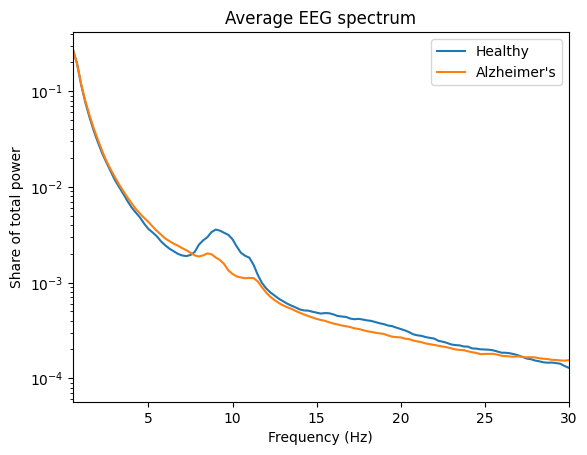

In [15]:
# Plots how much power each group has at each frequency, so you can see any difference
plt.plot(freqs_used, spectra[y == 0].mean(axis=0), label="Healthy")
plt.plot(freqs_used, spectra[y == 1].mean(axis=0), label="Alzheimer's")
plt.xlim(0.5, 30)
plt.yscale("log")                                     # log scale makes small differences easier to see
plt.xlabel("Frequency (Hz)")
plt.ylabel("Share of total power")
plt.title("Average EEG spectrum")
plt.legend()
plt.savefig("alz_spectrum.png", dpi=150, bbox_inches="tight")     # saves the picture for GitHub
plt.show()

In [16]:
# One row = one person, so every test below is on people that were not used for training
models = {
    "Logistic regression": LogisticRegression(C=0.1, max_iter=2000),
    "SVM": SVC(C=1.0),
    "Random forest": RandomForestClassifier(n_estimators=200, max_depth=3, random_state=0),
}
# 5-fold: split the 65 people into 5 groups, train on 4, test on the 1 left out, repeat for each group.
# Then do the whole thing 10 times with different splits and average the scores.
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)

print("Always guessing the bigger group:", round(max(y.mean(), 1 - y.mean()), 3))     # reference score for comparison
for name, model in models.items():
    scores = cross_val_score(make_pipeline(StandardScaler(), model), X, y, cv=cv)
    print(f"{name}: accuracy {scores.mean():.3f} (+/- {scores.std():.3f})")           # +/- shows how much the score changes between splits

Always guessing the bigger group: 0.554
Logistic regression: accuracy 0.795 (+/- 0.105)
SVM: accuracy 0.782 (+/- 0.110)
Random forest: accuracy 0.734 (+/- 0.123)


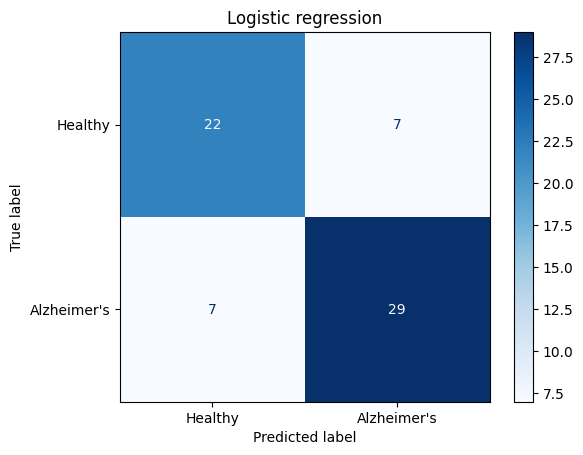

In [17]:
# Shows how many people of each group were predicted correctly and how many were mixed up.
# Change the model name below if another model scored best.
best = "Logistic regression"
pred = cross_val_predict(make_pipeline(StandardScaler(), models[best]), X, y,
                         cv=StratifiedKFold(5, shuffle=True, random_state=0))    # every prediction is on a person left out of training
ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=["Healthy", "Alzheimer's"], cmap="Blues")
plt.title(best)
plt.savefig("alz_confusion_matrix.png", dpi=150, bbox_inches="tight")             # saves the picture for GitHub
plt.show()

In [18]:
df.groupby("Group")["Age"].mean()

,Age
Group,
A,66.388889
C,67.896552
